# 06 Geography: maps of IT growth by metro, and are the QCEW metro codes stable?

Stream B3. Needs `data/processed/metro_panel.csv` (`python build_metro_panel.py`), the Census Gazetteer centroids
(`python collect.py --sources gazetteer`) and, for section 3, `data/raw/bls_qcew_areas_it_industries.csv`.

**Limits to keep in view**
- IT = NAICS 5415 (IT consulting and computer systems design). Software publishers and big tech are *not* in it.
- IT employment is withheld (suppressed) for Chicago, Houston, Atlanta, Minneapolis and St. Louis (and others); on the employment map they appear as grey crosses, **not as zero growth**.
- Positions are internal points of the 2023 CBSA delineation (Gazetteer). The outline is a hand-simplified drawing aid, not an official boundary.
- Only the lower 48 states are drawn; Alaska, Hawaii and Puerto Rico metros are counted in the footnote.

In [1]:
import os, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "build_master.py").exists())
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)      # the project's data paths are relative to the repo root
from collectors.common import RAW, PROCESSED
from analysis import geo

FIG = ROOT / "reports" / "figures"
HAVE_MAPS = (RAW / "census_gazetteer_cbsa.csv").exists()
if HAVE_MAPS:
    G = geo.load_geo_panel()
    cov = geo.coverage_report(G)
    print(cov["metros"], "metros in the panel;", cov["drawn"], "drawn,", cov["outside_lower48"], "outside the lower 48,",
          cov["without_centroid"], "without a centroid", cov["without_centroid_names"][:10])
else:
    # the maps need coordinates; section 3 (code stability) does not, so it still runs
    G = pd.read_csv(PROCESSED / "metro_panel.csv", dtype={"cbsa_code": str})
    print("NO CENTROIDS: data/raw/census_gazetteer_cbsa.csv is missing, so sections 1 and 2 (maps) are skipped.\n"
          "Get it with `python collect.py --sources gazetteer` (or save the zip in data/manual/); section 3 runs without it.")

403 metros in the panel; 390 drawn, 10 outside the lower 48, 3 without a centroid ['Madera, CA Metro Area', 'Ocean City, NJ Metro Area', 'San Germán, PR Metro Area']


## 1. IT employment growth 2019 to 2024
Bubble area = IT jobs in 2019, colour = growth (blue up, red down, white 0). Grey crosses: IT employment unusable (withheld in 2019 and/or 2024).

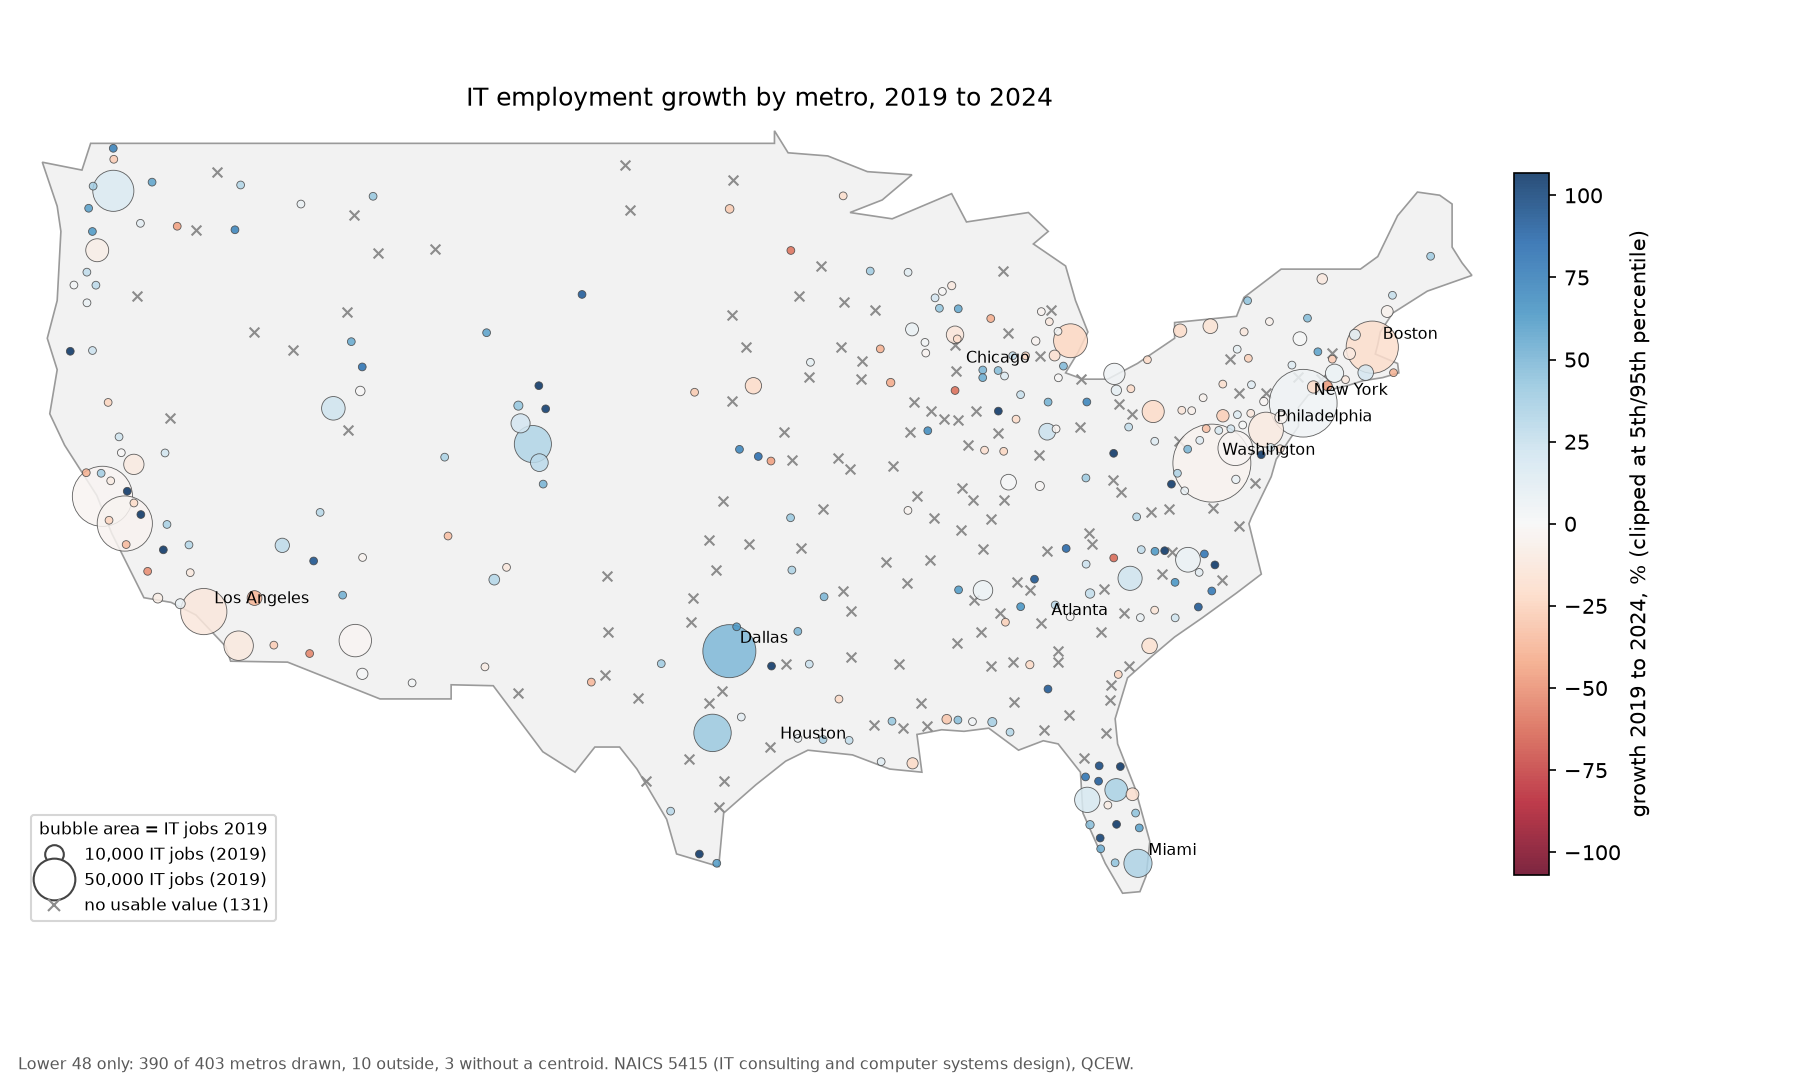

In [2]:
if HAVE_MAPS:
    paths = geo.make_maps(G, FIG)
    display(Image(filename=str(paths[0])))
else:
    print("skipped: no centroids")

## 2. IT establishment growth 2019 to 2024
Establishment counts are never withheld, so the five big missing metros are on this map. A hollow black outline means the 2019 job count is unknown, so the bubble has a fixed small size; where only the 2024 count is withheld (Chicago) the 2019 level still sizes the bubble.

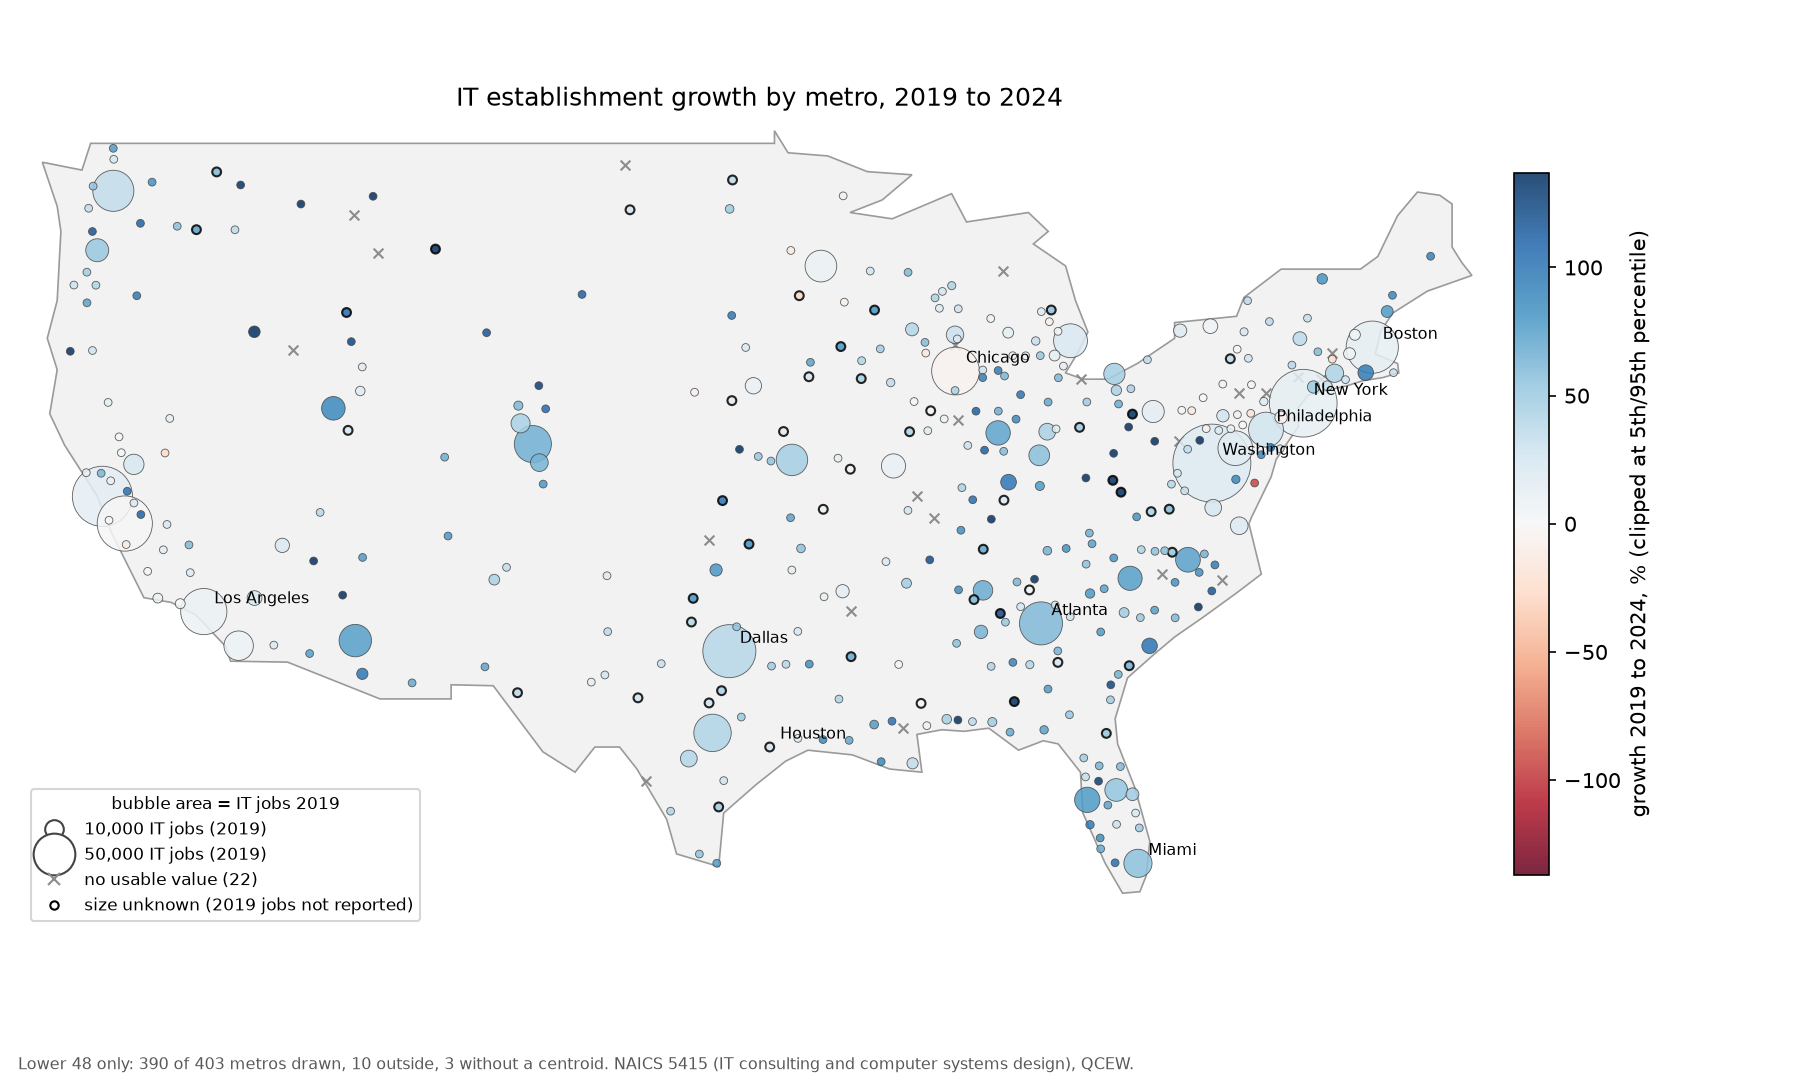

In [3]:
if HAVE_MAPS:
    display(Image(filename=str(paths[1])))
else:
    print('skipped: no centroids')

In [4]:
# The metros with no IT employment outcome: biggest first, and what we know about them anyway
miss = G[G["emp_basis"].eq("none")].nlargest(10, "emp_total_2019")
cols = [c for c in ["metro_name", "emp_total_2019", "emp_it_2019_reported", "estabs_it_2019", "estab_growth_pct"] if c in miss]
miss[cols].round(1)

,metro_name,emp_total_2019,emp_it_2019_reported,estabs_it_2019,estab_growth_pct
71,"Chicago-Naperville-Elgin, IL-IN-WI Metro Area",4029690.2,65543.8,6747.0,-3.5
165,"Houston-The Woodlands-Sugar Land, TX Metro Area",2637095.2,NaN,4282.0,25.3
20,"Atlanta-Sandy Springs-Alpharetta, GA Metro Area",2373950.9,53296.3,5515.0,60.1
240,"Minneapolis-St. Paul-Bloomington, MN-WI Metro ...",1706305.4,28836.8,2528.8,8.1
316,"St. Louis, MO-IL Metro Area",1179050.7,16782.3,1466.2,10.0
73,"Cincinnati, OH-KY-IN Metro Area",946342.9,12348.8,1744.0,56.8
186,"Kansas City, MO-KS Metro Area",904887.8,28444.9,2217.2,46.1
169,"Indianapolis-Carmel-Anderson, IN Metro Area",901526.5,17140.7,1410.0,71.7
84,"Columbus, OH Metro Area",883990.6,NaN,2001.8,49.8
256,"Nashville-Davidson--Murfreesboro--Franklin, TN...",879940.7,NaN,1589.0,71.6


## 3. Are the QCEW metro codes the same in 2019 and 2024?
QCEW codes metros `C####` (C + the first four digits of the CBSA code). The question is whether the set of codes changed with a new delineation
(new metros, merged or dropped ones). Two views: **any industry** (a code counts as present if it has any row that year) and **industry 10, all private employment**
(total employment is reported for every real area, so this is the cleaner test of the delineation itself).

In [5]:
a = pd.read_csv(RAW / "bls_qcew_areas_it_industries.csv", dtype=str, usecols=["area_fips", "year", "industry_code"], low_memory=False)
a["year"] = a["year"].astype(int)
stab_any = geo.code_stability(a)
stab_tot = geo.code_stability(a, industry="10")
names = {**dict(zip(G["cbsa_code"], G["metro_name"])), **{}}
yrs = [c for c in stab_tot.columns if c.startswith("y") and c[1:].isdigit()]
print("metro codes per year (industry 10):", {c[1:]: int(stab_tot[c].sum()) for c in yrs})
print("in both 2019 and 2024:", int(((stab_tot["only_in"] == "") & stab_tot["y2019"] & stab_tot["y2024"]).sum()),
      "| only 2019:", int((stab_tot["only_in"] == "2019").sum()), "| only 2024:", int((stab_tot["only_in"] == "2024").sum()))
one = geo.only_one_year(stab_tot, names)
one.to_csv(PROCESSED / "qcew_metro_code_stability.csv", index=False)
one[["area_fips", "cbsa_code", "only_in", "name", *yrs]] if len(one) else print("No metro code is present in only one of the two years.")

metro codes per year (industry 10): {'2015': 388, '2016': 388, '2017': 388, '2018': 388, '2019': 388, '2020': 388, '2021': 388, '2022': 388, '2023': 388, '2024': 393, '2025': 393}
in both 2019 and 2024: 373 | only 2019: 15 | only 2024: 20


,area_fips,cbsa_code,only_in,name,y2015,y2016,y2017,y2018,y2019,y2020,y2021,y2022,y2023,y2024,y2025
0,C1410,14100,2019,"Bloomsburg-Berwick, PA Metro Area",True,True,True,True,True,True,True,True,True,False,False
1,C1568,15680,2019,NaN,True,True,True,True,True,True,True,True,True,False,False
2,C1606,16060,2019,"Carbondale-Marion, IL Metro Area",True,True,True,True,True,True,True,True,True,False,False
3,C1746,17460,2019,NaN,True,True,True,True,True,True,True,True,True,False,False
4,C1906,19060,2019,"Cumberland, MD-WV Metro Area",True,True,True,True,True,True,True,True,True,False,False
5,C1918,19180,2019,"Danville, IL Metro Area",True,True,True,True,True,True,True,True,True,False,False
6,C1938,19380,2019,NaN,True,True,True,True,True,True,True,True,True,False,False
7,C2070,20700,2019,"East Stroudsburg, PA Metro Area",True,True,True,True,True,True,True,True,True,False,False
8,C3146,31460,2019,"Madera, CA Metro Area",True,True,True,True,True,True,True,True,True,False,False
9,C3510,35100,2019,"New Bern, NC Metro Area",True,True,True,True,True,True,True,True,True,False,False


In [6]:
# Same check with any industry (should be a subset of the above plus codes that only have IT rows in one year)
only_any = geo.only_one_year(stab_any, names)
extra = sorted(set(only_any["area_fips"]) - set(one["area_fips"]))
print(len(only_any), "codes in only one year (any industry);", len(extra), "of them are not in the all-industries list:", extra[:15])

35 codes in only one year (any industry); 0 of them are not in the all-industries list: []


In [7]:
# What a code check cannot see: a code that stays the same while its counties change. Heuristic: extreme total-employment change.
if "total_growth_pct" in G:
    flag = G.assign(abs_g=G["total_growth_pct"].abs()).nlargest(10, "abs_g")[["cbsa_code", "metro_name", "emp_total_2019", "total_growth_pct"]]
    display(flag.round(1))

,cbsa_code,metro_name,emp_total_2019,total_growth_pct
230,32420,"Mayagüez, PR Metro Area",22994.3,92.3
319,41540,"Salisbury, MD-DE Metro Area",137638.7,-69.7
212,30500,"California-Lexington Park, MD Metro Area",30536.8,66.9
394,48900,"Wilmington, NC Metro Area",107840.4,51.5
227,31740,"Manhattan, KS Metro Area",28756.0,31.6
392,48680,"The Villages, FL Metro Area",26177.3,29.1
21,12100,"Atlantic City-Hammonton, NJ Metro Area",109156.5,28.7
174,27180,"Jackson, TN Metro Area",52837.9,26.8
350,44140,"Springfield, MA Metro Area",229430.2,-26.1
314,41100,"St. George, UT Metro Area",61078.7,24.8


In [8]:
n19, n24 = int((one["only_in"] == "2019").sum()), int((one["only_in"] == "2024").sum())
print(f"- Answer (c): {'the metro code set is identical in 2019 and 2024' if n19 + n24 == 0 else f'{n19} metro codes appear only in 2019 and {n24} only in 2024 (list above and in data/processed/qcew_metro_code_stability.csv)'}.")
print("- Limit: this tests the codes, not the boundaries. The QCEW area file has no county list, so a metro that keeps its code but gains or loses counties is not detectable here;"
      " the extreme-total-growth table above is only a hint.")
print("- Consequence for the panel: metros present in one year only cannot have a 2019-to-2024 growth and are already excluded from the usable sets.")

- Answer (c): 15 metro codes appear only in 2019 and 20 only in 2024 (list above and in data/processed/qcew_metro_code_stability.csv).
- Limit: this tests the codes, not the boundaries. The QCEW area file has no county list, so a metro that keeps its code but gains or loses counties is not detectable here; the extreme-total-growth table above is only a hint.
- Consequence for the panel: metros present in one year only cannot have a 2019-to-2024 growth and are already excluded from the usable sets.
